# [Lab Session 2](otsu.ipynb)

In [4]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 2.1.]()** Implement Otsu thresholding as a re-usable function:

In [5]:
def otsu_thresholding(imgf):
    img8 = (imgf * 255).round().astype(np.uint8)


    h = np.zeros(256)

    for i in range(256):
        h[i] = np.sum(img8 == i)

        sum_wcv = np.zeros(256)

    for T in range (256):
         sum_wcv[T] = (np.sum(h[:T])*np.var(img8[img8 < T]) + (np.sum(h[T:])*np.var(img8[img8 >=T])))

    
    T_best = np.nanargmin(sum_wcv)

    img_2 = img8.copy()  
 

    for x in range(1024):
        for y in range(1344):
            if img_2[x,y] >= T_best:
                img_2[x,y] = 1
            else :
                img_2[x,y] = 0 
   
    
    return img_2

**[Task 2.2.]()** Implement a re-usable function to compute the Dice coefficient:

In [6]:
#def compute_dice(bin1,bin2):
    #assert bin1.dtype == bool
    #assert bin2.dtype == bool
    
    #img8.shape
    #img_2 = img8.copy()

    #G = bin1
    #H = bin2

    #GH = G*H

    #gt = plt.imread('data/NIH3T3/gt/0.png').astype(bool)

    #dice = 2 * (G * H).sum() / (G.sum() + H.sum())

    #return dice

def compute_dice(G, H):
    assert G.dtype == bool and H.dtype == bool
    dice = 2 * (G * H).sum() / (G.sum() + H.sum())
    return dice


  

    

**[Task 2.3.]()** Test your implementations from above:

/usr/local/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3787: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


0.8943783223933183


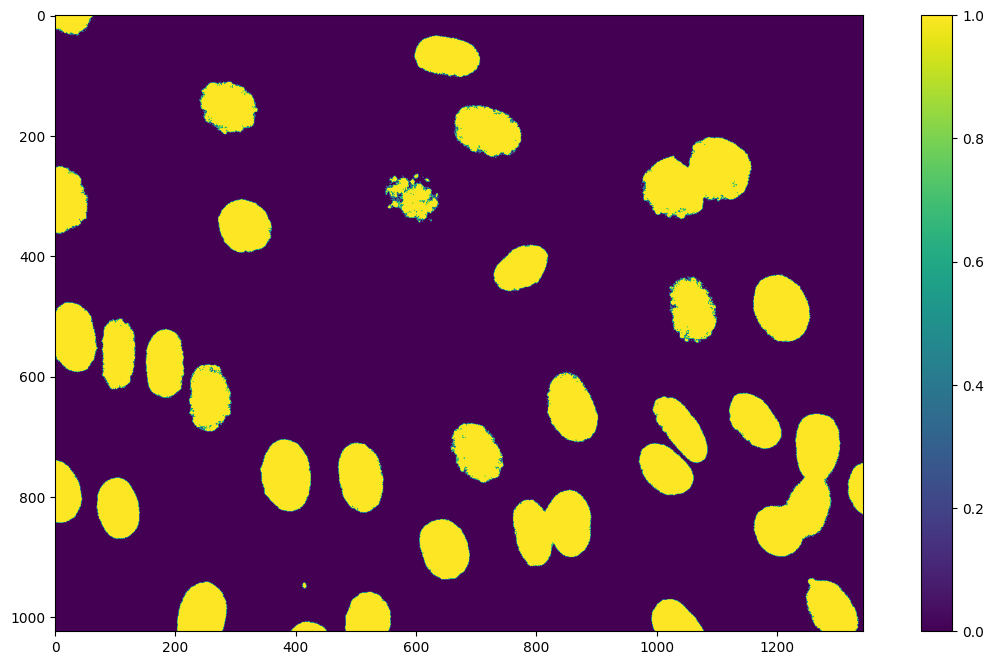

In [117]:
img5= plt.imread('data/NIH3T3/im/dna-0.png')
gt_5 = plt.imread('data/NIH3T3/gt/0.png')


a = otsu_thresholding(img5)
b = compute_dice(a.astype(bool), gt_5.astype(bool))



plt.figure(figsize=(15,8))
plt.imshow(a)
plt.colorbar()

print(b)



The result should be the same as in your [otsu.ipynb](otsu.ipynb) notebook.

**[Task 2.4.]()** Perform batch processing:

In [10]:
indices = [28, 29, 33, 44, 46, 49]
dice_scores = []

for i in indices:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png')

    seg = otsu_thresholding(img).astype(bool)
    gt_mask = gt > 0                            

    d = compute_dice(gt_mask, seg)
    dice_scores.append(d)
    print(f'Bild {i}: Dice = {d:.4f}')

/usr/local/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3787: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Bild 28: Dice = 0.7529
Bild 29: Dice = 0.6476
Bild 33: Dice = 0.4300
Bild 44: Dice = 0.5789
Bild 46: Dice = 0.0761
Bild 49: Dice = 0.7965
